# Dyslexia Error-Pattern Classifier
**Goal:** Given the word a person *meant* to spell and what they *actually typed*, label the mistake as a pattern.

| Label | Meaning | Example (meant → typed) |
|---|---|---|
| reversal | Mirror-letter swap (b/d, p/q) | bed → ded |
| transposition | Two neighbouring letters swapped | form → from |
| omission | One letter missing | friend → frend |
| phonetic | Spelled the way it sounds | phone → fone |
| other | Anything that fits none of the above | accordingly → o |

**Pipeline:** Get real data → clean → label → turn into numbers → split X/y → split train/test → build 2 models → compare → visualise → live demo.

## **SETUP**


### Install the sound-matching library

In [ ]:
!pip install -q jellyfish

### Import the libraries

In [ ]:
import re
import urllib.request
import difflib
import pandas as pd
import jellyfish
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## **GETTING THE DATASET**

## Download Corpus files

In [ ]:
BASE_URL = "https://titan.dcs.bbk.ac.uk/~roger/"
files = ["missp.dat", "aspell.dat", "wikipedia.dat"]
for name in files:
    # Download the file from the website and save it in Colab under the same name.
    urllib.request.urlretrieve(BASE_URL + name, name)
    # Tell us it worked.
    print("Downloaded:", name)

Downloaded: missp.dat
Downloaded: aspell.dat
Downloaded: wikipedia.dat


## Read files into a table

In [ ]:
# Define a reusable function. It takes the file name and a label saying which corpus it came from.
def read_corpus(path, source):
    # An empty list where we will collect all the (meant, typed) pairs.
    pairs = []
    # Remember the "current correct word" while reading. Starts as nothing.
    target = None
    # Open the file. latin-1 is an old text encoding that never crashes on odd characters.
    with open(path, encoding="latin-1") as f:
        # Read the file one line at a time.
        for line in f:
            # Remove spaces/newlines at both ends of the line.
            line = line.strip()
            # If the line is empty, skip it.
            if not line:
                continue
            # A line starting with $ means "this is the CORRECT word".
            if line.startswith("$"):
                # Save the correct word (without the $ sign) for the lines that follow.
                target = line[1:].split()[0]
            # Otherwise, the line is a MISSPELLING of the current correct word.
            elif target is not None:
                # Store the trio: correct word, misspelling, and which corpus it came from.
                pairs.append((target, line.split()[0], source))
    # Give back the full list.
    return pairs

# Read each file and join the three lists into one big list.
rows = (read_corpus("missp.dat", "birkbeck")
        + read_corpus("aspell.dat", "aspell")
        + read_corpus("wikipedia.dat", "wikipedia"))

# Put everything in a table with 3 named columns.
raw = pd.DataFrame(rows, columns=["target", "typed", "source"])

# Show the first 10 rows and the total row count.
print("Total pairs read:", len(raw))
raw.head(10)

Total pairs read: 39119


,target,typed,source
0,Albert,Ab,birkbeck
1,America,Ameraca,birkbeck
2,America,Amercia,birkbeck
3,American,Ameracan,birkbeck
4,April,Apirl,birkbeck
5,Austrian,Austrain,birkbeck
6,Badcock's,badcock,birkbeck
7,Bechuanaland,bechuarnia_land,birkbeck
8,Botswana,botuania,birkbeck
9,Cambridge,Cambrige,birkbeck


## Clean the Data

In [ ]:
# Function that keeps only a-z letters in lowercase and throws away everything else.
def clean(word):
    # word.lower() makes it lowercase; re.sub deletes any character that is NOT a-z.
    return re.sub(r"[^a-z]", "", word.lower())

# Apply the cleaning to both columns.
raw["target"] = raw["target"].map(clean)
raw["typed"] = raw["typed"].map(clean)

# Keep only rows where both words are non-empty AND the "mistake" is actually different from the target.
raw = raw[(raw["target"].str.len() > 0) &
          (raw["typed"].str.len() > 0) &
          (raw["target"] != raw["typed"])]

# Remove duplicate pairs (the same pair may appear in more than one file) and renumber the rows.
raw = raw.drop_duplicates(subset=["target", "typed"]).reset_index(drop=True)

# Show how many clean pairs we have left.
print("Clean pairs:", len(raw))

Clean pairs: 37734


# 4. Labelling the Errors
The corpus doesn't say what kind of mistake each one is, so we define each type precisely. Rules are checked **in this order**; the first match wins:

1. **reversal**: same length, exactly one letter differs, and it is b↔d or p↔q
2. **transposition**: same length, exactly two neighbouring letters differ and they are swapped
3. **omission**: typed word is one letter shorter and equals the target with one letter deleted
4. **phonetic**: Metaphone ("sound code") of both words is identical
5. **other**: none of the above

In [ ]:
# The mirror-letter pairs that count as dyslexic-style reversals.
MIRROR = {("b", "d"), ("d", "b"), ("p", "q"), ("q", "p")}

# Function that takes the meant word and typed word and returns the error label.
def label_error(target, typed):
    # Reversal and transposition only happen when both words have the same length.
    if len(target) == len(typed):
        # Make a list of the positions where the two words have different letters.
        diff = [i for i in range(len(target)) if target[i] != typed[i]]
        # Exactly one different position AND that letter pair is a mirror pair -> reversal.
        if len(diff) == 1 and (target[diff[0]], typed[diff[0]]) in MIRROR:
            return "reversal"
        # Exactly two different positions, side by side, and the letters are swapped -> transposition.
        if (len(diff) == 2 and diff[1] == diff[0] + 1
                and target[diff[0]] == typed[diff[1]]
                and target[diff[1]] == typed[diff[0]]):
            return "transposition"
    # Omission: the typed word is exactly one letter shorter.
    if len(typed) == len(target) - 1:
        # Try deleting each letter of the target; if any result equals what was typed -> omission.
        if any(target[:i] + target[i+1:] == typed for i in range(len(target))):
            return "omission"
    # Phonetic: get the "sound code" of the meant word.
    sound = jellyfish.metaphone(target)
    # If the code exists and the typed word has the SAME code, it sounds alike -> phonetic.
    if sound and sound == jellyfish.metaphone(typed):
        return "phonetic"
    # Nothing matched.
    return "other"

# Apply the function to every row and store the answers in a new "label" column.
raw["label"] = [label_error(t, y) for t, y in zip(raw["target"], raw["typed"])]

# Show how many of each label we got.
print(raw["label"].value_counts())

label
other            20819
phonetic         12448
omission          4732
transposition     1090
reversal            30
Name: count, dtype: int64


## Sanity Check

In [ ]:
# Go through each label name.
for lab in raw["label"].unique():
    # Print the label as a heading.
    print("\n==", lab, "==")
    # Pick up to 5 random rows with that label and print only the two word columns.
    sample = raw[raw["label"] == lab].sample(min(5, (raw["label"] == lab).sum()), random_state=1)
    print(sample[["target", "typed"]].to_string(index=False))


== other ==
         target          typed
       suitable       sterball
 affectionately   affecentally
    fascinating    vasintiting
    necessarily      nessaryly
congratulations congratalation

== phonetic ==
    target      typed
apparently apparntely
eventually  evendully
  guardian   gurriden
     folly     follie
  specific   Specific

== transposition ==
 target   typed
 minute  minuet
    who     hwo
shields sheilds
bicycle bicycel
  tired   tried

== omission ==
     target      typed
   agencies    agecies
      vague       vage
     honest      onest
recommended recomended
      until       untl

== reversal ==
target typed
    do    bo
   job   jod
   big   dig
  down  bown
   day   bay


## Charts

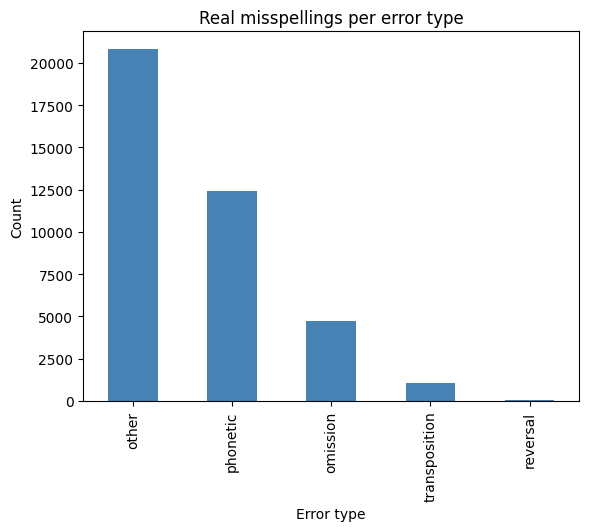

In [ ]:
# Count rows per label and draw them as a bar chart.
raw["label"].value_counts().plot(kind="bar", color="steelblue")
# Title and axis names so the chart is readable.
plt.title("Real misspellings per error type")
plt.xlabel("Error type")
plt.ylabel("Count")
# Show the chart.
plt.show()


# TURNING WORD PAIRS INTO NUMBERS

| Clue | What it tells the model |
|---|---|
| len_diff | Negative = typed word is shorter |
| same_letters | 1 = same letters, only reordered |
| n_replace / n_delete / n_insert | How many edits of each kind |
| mirror_swaps | How many b/d or p/q flips |
| mismatches | How many positions differ (same-length words only) |
| sound_match | 1 = words sound alike (Metaphone) |
| similarity | 0 to 1, how alike the spellings look |
| first_letter_same | 1 = the first letter is correct |

In [ ]:
# Function that turns ONE (meant, typed) pair into a dictionary of clue numbers.
def extract_features(target, typed):
    # SequenceMatcher compares the two words; get_opcodes() lists the edits needed (equal/replace/delete/insert).
    ops = difflib.SequenceMatcher(None, target, typed).get_opcodes()
    # Start all counters at zero.
    n_replace = n_delete = n_insert = mirror_swaps = 0
    # Look at each edit step. i1:i2 is the piece of the meant word, j1:j2 the matching piece of the typed word.
    for tag, i1, i2, j1, j2 in ops:
        # A letter was swapped for another.
        if tag == "replace":
            n_replace += 1
            # If that swap was a mirror pair (b/d or p/q), count it.
            if (target[i1:i2], typed[j1:j2]) in MIRROR:
                mirror_swaps += 1
        # A letter was removed.
        elif tag == "delete":
            n_delete += 1
        # A letter was added.
        elif tag == "insert":
            n_insert += 1
    # If both words have the same length, count how many positions differ; otherwise put 0 ("not applicable").
    if len(target) == len(typed):
        mismatches = sum(1 for a, b in zip(target, typed) if a != b)
    else:
        mismatches = 0
    # Return all the clues, each with a name.
    return {
        "len_diff": len(typed) - len(target),                                    # shorter or longer?
        "same_letters": int(sorted(target) == sorted(typed)),                    # same letters, reordered?
        "n_replace": n_replace,                                                  # number of replaced letters
        "n_delete": n_delete,                                                    # number of deleted letters
        "n_insert": n_insert,                                                    # number of added letters
        "mirror_swaps": mirror_swaps,                                            # number of b/d, p/q flips
        "mismatches": mismatches,                                                # differing positions
        "sound_match": int(jellyfish.metaphone(target) == jellyfish.metaphone(typed)),  # sounds the same?
        "similarity": difflib.SequenceMatcher(None, target, typed).ratio(),      # how similar overall (0-1)
        "first_letter_same": int(target[0] == typed[0]),                         # first letter correct?
    }

## Apply to Whole Database

In [ ]:
# Run extract_features on every row; the result is a list of dictionaries.
feature_rows = [extract_features(t, y) for t, y in zip(raw["target"], raw["typed"])]

# Turn that list into a table: one row per word pair, one column per clue.
features_df = pd.DataFrame(feature_rows)

# Show the first 10 rows.
features_df.head(10)

,len_diff,same_letters,n_replace,n_delete,n_insert,mirror_swaps,mismatches,sound_match,similarity,first_letter_same
0,-4,0,0,2,0,0,0,0,0.500000,1
1,0,0,1,0,0,0,1,1,0.857143,1
2,0,1,0,1,1,0,2,0,0.857143,1
3,0,0,1,0,0,0,1,1,0.875000,1
4,0,1,0,1,1,0,2,1,0.800000,1
5,0,1,0,1,1,0,2,1,0.875000,1
6,-2,0,1,1,0,0,0,0,0.750000,0
7,3,0,1,0,3,0,0,0,0.814815,0
8,0,0,2,0,1,0,5,0,0.625000,0
9,-1,0,0,1,0,0,0,1,0.941176,1


## Split into x and y

In [ ]:
# X = the table of clue numbers.
X = features_df
# y = the label column (the "answers").
y = raw["label"]
# Show sizes as (rows, columns).
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (39119, 10)
y shape: (39119,)


# Split into Training and Test Sets

In [ ]:
# test_size=0.2 -> 20% for the exam. random_state=42 -> same split every run.
# stratify=y -> keep the same mix of error types in both parts (important because some types are rare).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# Show how big each part is.
print("Training rows:", len(X_train))
print("Testing rows: ", len(X_test))

Training rows: 31295
Testing rows:  7824


# Model Building
## Logistic Regression

In [ ]:
# Create the model. max_iter=2000 = allow enough learning steps. class_weight="balanced" = care about rare classes.
lr_model = LogisticRegression(max_iter=2000, class_weight="balanced")
# .fit() = "study time": learn the link between clues (X_train) and answers (y_train).
lr_model.fit(X_train, y_train)
# .predict() = "exam time": guess labels for the unseen test data.
lr_pred = lr_model.predict(X_test)
# Compare guesses with the real answers; print the % correct.
lr_acc = accuracy_score(y_test, lr_pred)
print("Logistic Regression accuracy:", round(lr_acc, 3))

Logistic Regression accuracy: 0.993


## Random Forest

In [ ]:
# Create a forest of 100 trees. random_state makes results repeatable.
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
# Train it.
rf_model.fit(X_train, y_train)
# Predict the test set.
rf_pred = rf_model.predict(X_test)
# Measure accuracy.
rf_acc = accuracy_score(y_test, rf_pred)
print("Random Forest accuracy:", round(rf_acc, 3))

Random Forest accuracy: 0.999



# MODEL COMPARISON

In [ ]:
# Put both scores side by side in a small table.
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [lr_acc, rf_acc]
})
# Display it.
comparison

print("Logistic Regression\n", classification_report(y_test, lr_pred))
print("Random Forest\n", classification_report(y_test, rf_pred))

Logistic Regression
                precision    recall  f1-score   support

     omission       1.00      1.00      1.00       946
        other       1.00      0.99      1.00      4164
     phonetic       1.00      0.99      0.99      2490
     reversal       0.75      1.00      0.86         6
transposition       0.83      1.00      0.90       218

     accuracy                           0.99      7824
    macro avg       0.91      1.00      0.95      7824
 weighted avg       0.99      0.99      0.99      7824

Random Forest
                precision    recall  f1-score   support

     omission       1.00      1.00      1.00       946
        other       1.00      1.00      1.00      4164
     phonetic       1.00      1.00      1.00      2490
     reversal       1.00      1.00      1.00         6
transposition       0.96      1.00      0.98       218

     accuracy                           1.00      7824
    macro avg       0.99      1.00      1.00      7824
 weighted avg       1.00

# DATA VISUALIZATION

## Confusion Matrix

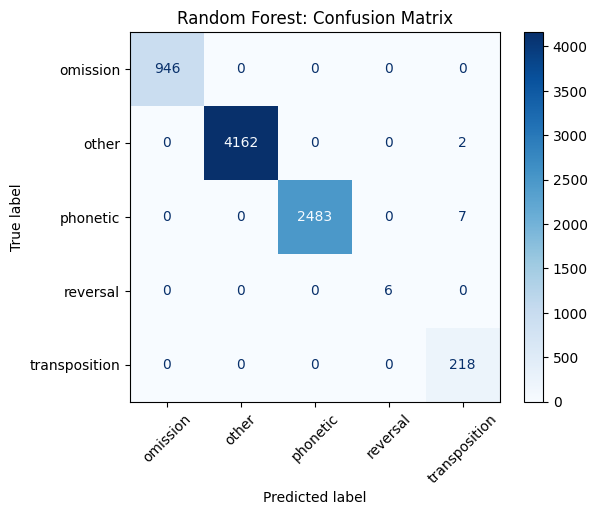

In [ ]:
# Draw the confusion matrix from the true answers and the Random Forest predictions.
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, cmap="Blues", xticks_rotation=45)
# Title and display.
plt.title("Random Forest: Confusion Matrix")
plt.show()

## Which Clues mattered most

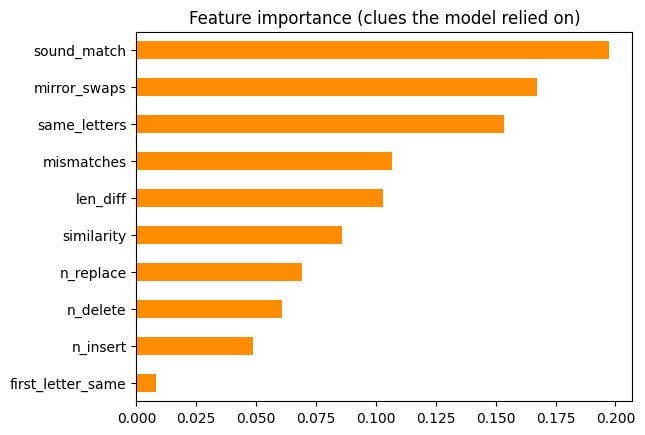

In [ ]:
# The forest scores how useful each clue was. Pair the scores with clue names and sort them.
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
# Draw as horizontal bars.
importance.plot(kind="barh", color="darkorange")
# Title and display.
plt.title("Feature importance (clues the model relied on)")
plt.show()

# LIVE DEMO

In [ ]:
# Helper that runs the whole pipeline on ONE pair of words.
def classify_error(target, typed):
    # Clean both words the same way we cleaned the training data.
    target, typed = clean(target), clean(typed)
    # Turn them into a one-row table of clues, with columns in the same order as training.
    clues = pd.DataFrame([extract_features(target, typed)])[X.columns]
    # Ask the Random Forest for its answer and return it.
    return rf_model.predict(clues)[0]

# Try your own examples during the presentation.
print("bed -> ded       :", classify_error("bed", "ded"))
print("form -> from     :", classify_error("form", "from"))
print("friend -> frend  :", classify_error("friend", "frend"))
print("phone -> fone    :", classify_error("phone", "fone"))

bed -> ded       : reversal
form -> from     : transposition
friend -> frend  : omission
phone -> fone    : phonetic
